---
title: "Practice Activity 12-1: Linear Classifiers"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    html-math-method: mathml
    code-overflow: wrap
---


## The Data

At this link, you will find a dataset containing information about heart disease patients: https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1

A description of the original dataset can be found here: https://archive.ics.uci.edu/dataset/45/heart+disease (However, this dataset has been cleaned and reduced, and the people have been given fictious names.)

## 1. Logistic Regression

Fit a Logistic Regression using only `age` and `chol` (cholesterol) as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

How high for the doctors to estimate a 90% chance that heart disease is present?

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

url = (
    "https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv"
    "?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1"
)
heart = pd.read_csv(url)

X = heart[["age", "chol"]]
y = heart["diagnosis"].eq("Disease").astype(int)

logistic_model = LogisticRegression(solver="newton-cg").fit(X, y)
intercept = logistic_model.intercept_[0]
age_coef, chol_coef = logistic_model.coef_[0]

chol_50 = (0 - intercept - age_coef * 55) / chol_coef
chol_90 = (np.log(0.9 / 0.1) - intercept - age_coef * 55) / chol_coef

print(f"Cholesterol at 50%: {chol_50:.2f} mg/dL")
print(f"Cholesterol at 90%: {chol_90:.2f} mg/dL")
print(f"Cholesterol coefficient: {chol_coef:.6f}")

Cholesterol at 50%: 368.04 mg/dL
Cholesterol at 90%: -853.62 mg/dL
Cholesterol coefficient: -0.001799


**Answer:** For a 55-year-old, our model predicts a 50% chance of heart disease at about 368 mg/dL. The predicted probability is above 50% when cholesterol is below this cutoff. To reach 90%, the model would require a cholesterol level of about −854 mg/dL, so there is no valid cholesterol level that gives a 90% prediction.

## 2. Linear Discriminant Analysis

Fit an LDA model using only `age` and `chol` (cholesterol)  as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [2]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_model = LinearDiscriminantAnalysis().fit(X, y)

lda_intercept = lda_model.intercept_[0]
lda_age_coef, lda_chol_coef = lda_model.coef_[0]

lda_chol_cutoff = -(lda_intercept + lda_age_coef * 55) / lda_chol_coef

print(f"LDA cholesterol cutoff: {lda_chol_cutoff:.2f} mg/dL")
print(f"LDA cholesterol coefficient: {lda_chol_coef:.6f}")

LDA cholesterol cutoff: 368.24 mg/dL
LDA cholesterol coefficient: -0.001790


**Answer:** For a 55-year-old, our LDA model predicts heart disease when cholesterol is below about 368.24 mg/dL.

## 3. Support Vector Classifier

Fit an SVC model using only `age` and `chol` as predictors.  Don't forget to tune the regularization parameter.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [3]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svc_pipeline = make_pipeline(StandardScaler(), SVC(kernel="linear"))
svc_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

svc_search = GridSearchCV(
    svc_pipeline,
    {"svc__C": [0.01, 0.1, 1, 10, 100]},
    scoring="accuracy",
    cv=svc_cv,
).fit(X, y)

svc_model = svc_search.best_estimator_
svc_scaler = svc_model.named_steps["standardscaler"]
svc_classifier = svc_model.named_steps["svc"]

svc_coefs = svc_classifier.coef_[0] / svc_scaler.scale_
svc_age_coef, svc_chol_coef = svc_coefs
svc_intercept = svc_classifier.intercept_[0] - svc_coefs @ svc_scaler.mean_

print(f"Best C: {svc_search.best_params_['svc__C']}")
print(f"Mean CV accuracy: {svc_search.best_score_:.4f}")
print(f"Cholesterol coefficient: {svc_chol_coef:.8g}")

if svc_chol_coef == 0:
    print("At age 55, the prediction does not depend on cholesterol.")
else:
    svc_chol_cutoff = -(svc_intercept + 55 * svc_age_coef) / svc_chol_coef
    print(f"Cholesterol cutoff at age 55: {svc_chol_cutoff:.2f} mg/dL")

Best C: 1
Mean CV accuracy: 0.5933
Cholesterol coefficient: -0.0036534409
Cholesterol cutoff at age 55: 312.71 mg/dL


**Answer:** We selected C = 1 using 5-fold cross-validation. For a 55-year-old, our SVC model predicts heart disease when cholesterol is below about 312.71 mg/dL.

## 4. Comparing Decision Boundaries

Make a scatterplot of `age` and `chol`, coloring the points by their true disease outcome.  Add a line to the plot representing the **linear separator** (aka **decision boundary**) for each of the three models above.

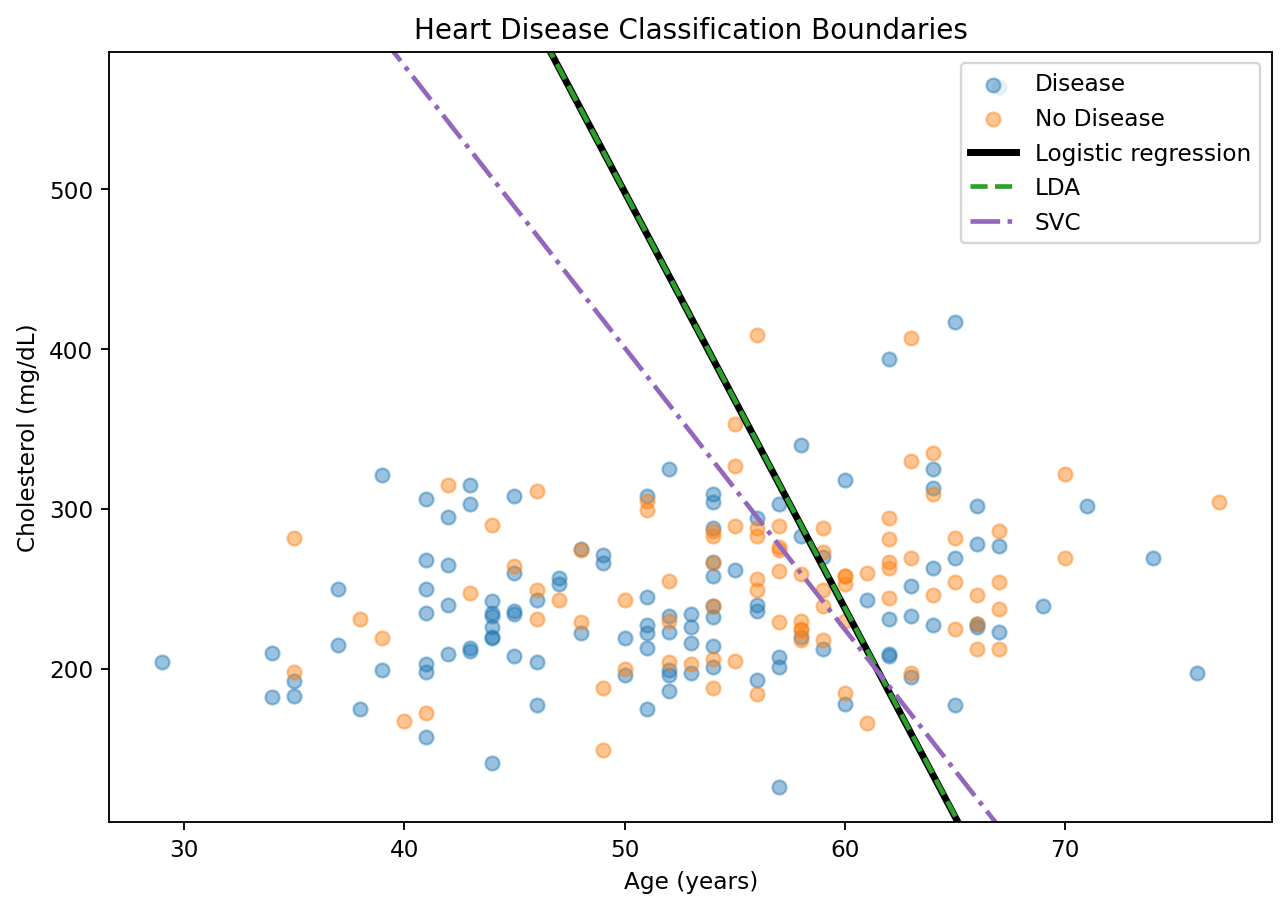

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

for diagnosis, group in heart.groupby("diagnosis"):
    ax.scatter(group["age"], group["chol"], alpha=0.45, label=diagnosis)

chol_limits = ax.get_ylim()
age_range = np.array([X["age"].min(), X["age"].max()])

boundaries = [
    ("Logistic regression", intercept, age_coef, chol_coef, "black", "-", 3),
    ("LDA", lda_intercept, lda_age_coef, lda_chol_coef, "tab:green", "--", 2),
    ("SVC", svc_intercept, svc_age_coef, svc_chol_coef, "tab:purple", "-.", 2),
]

for name, bias, age_weight, chol_weight, color, style, width in boundaries:
    chol_boundary = -(bias + age_weight * age_range) / chol_weight
    ax.plot(
        age_range, chol_boundary, color=color, linestyle=style,
        linewidth=width, label=name
    )

ax.set(
    title="Heart Disease Classification Boundaries",
    xlabel="Age (years)",
    ylabel="Cholesterol (mg/dL)",
    ylim=chol_limits,
)
ax.legend()
plt.show()